## Final takeaway

The mathematics changes gradually across the four examples:

1. **One variable:** calculate an ordinary derivative and interpret its tangent slope.
2. **One variable with a composed loss:** use the chain rule to connect error and weight.
3. **Two variables:** calculate a separate partial derivative for each variable, holding the other fixed.
4. **Two variables in a neural-network loss:** use the chain rule to calculate both gradients, then apply the same gradient-descent update idea.

The key distinction is not that partial derivatives are a different kind of learning algorithm. **They are the individual slope calculations required when a function depends on more than one independently adjustable parameter.**


## 8. Concept checks

**Q1. How does the derivative of a function differ from the graph of the function itself?**

The function graph gives the output value at each input. The derivative graph gives the **local slope** at each input. For the square function, the graph is a parabola, while the derivative graph is a straight line.

**Q2. Why is the second term treated as zero when differentiating `w1 squared + 2 times w2 squared` with respect to w1?**

A partial derivative with respect to w1 holds w2 constant. A term containing only w2 therefore does not change when w1 changes, so its contribution to that partial derivative is zero.

**Q3. Why are two partial derivatives needed for the two-weight regression loss?**

The loss depends on two independently adjustable weights. One derivative measures sensitivity when the first weight changes and the second stays fixed. The other measures sensitivity when the second weight changes and the first stays fixed.

**Q4. Does a positive gradient mean that gradient descent should increase the corresponding weight?**


No. A positive gradient means a small increase in that weight would increase the loss locally. Standard gradient descent subtracts the learning rate times the gradient, so a positive gradient produces a negative update for that weight.

**Q5. Does calculating a gradient update the network weights?**

No. Backpropagation calculates gradients. A separate optimization step, such as gradient descent, uses those gradients and a learning rate to update weights.



In [ ]:
%pip install numpy matplotlib
%pip install sympy
%pip install pandas scikit-learn
%pip install keras tensorflow

In [ ]:
import numpy
import matplotlib
import sympy

print("Lecture libraries imported successfully.")

Lecture libraries imported successfully.


In [ ]:
import pandas
import sklearn
import keras
import tensorflow

print("Pair-programming libraries imported successfully.")
print("Keras backend:", keras.config.backend())

Pair-programming libraries imported successfully.
Keras backend: tensorflow


**1. What does a derivative measure?**

**Part A: Ordinary derivatives: one independent variable**

**2. Ordinary derivative, Example 1: A simple square function **

2.1 Start with the function: $$f(w)=w^2$$

At w=2, a small increase in w mak f(w) lager.

**2.2 Calculate the derivative by hand**
f'(w) = 2w + h

**2.3 Evaluate the derivative at a point**
At w =2:

f(2)= 4

f'(2) = 2 .2 = 4

**2.4 Calculate the same derivative in Python**

In [ ]:
import sympy as sp

w = sp.symbols("w")
f = w**2

# Differentiate with respect to w.
df_dw = sp.diff(f, w)

# Evaluate the function and its derivative at w = 2.
print("Function:", f)
print("Derivative:", df_dw)
print("f(2) =", f.subs(w, 2))
print("f'(2) =", df_dw.subs(w, 2))

Function: w**2
Derivative: 2*w
f(2) = 4
f'(2) = 4


**2.5 Visualize the function and its derivative**

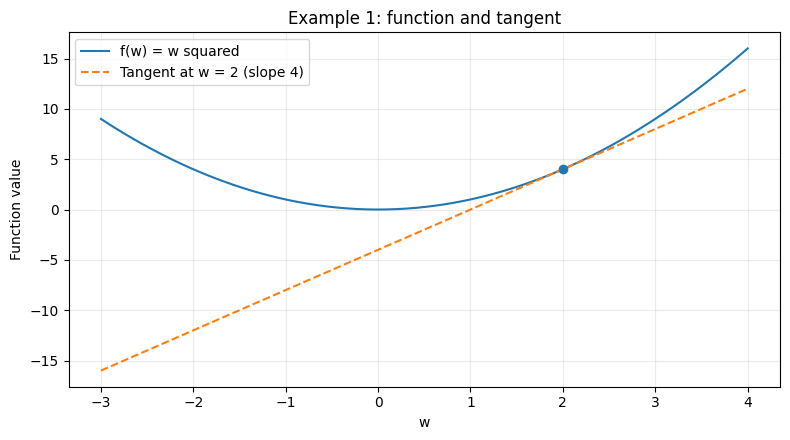

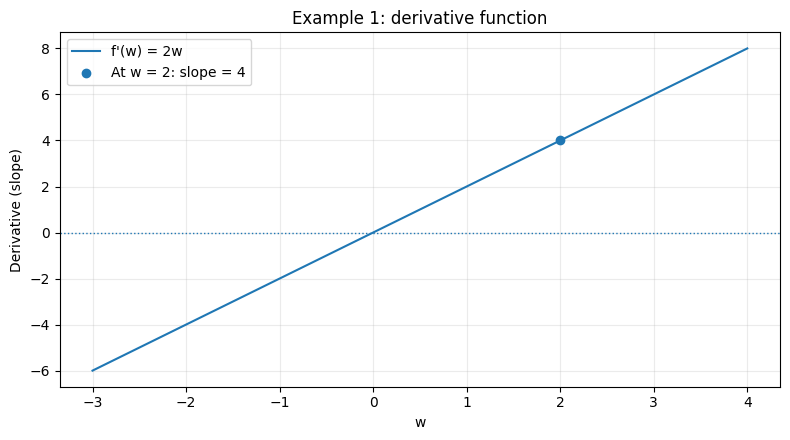

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

w = np.linspace(-3.0, 4.0, 400)
function = w**2
derivative = 2*w

point = 2.0
point_value = point**2
point_slope = 2*point

tangent = point_value + point_slope*(w - point)

# Plot A: original function and tangent line.
plt.figure(figsize=(8, 4.5))
plt.plot(w, function, label="f(w) = w squared")
plt.plot(w, tangent, "--", label="Tangent at w = 2 (slope 4)")
plt.scatter([point], [point_value], zorder=3)
plt.xlabel("w")
plt.ylabel("Function value")
plt.title("Example 1: function and tangent")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Plot B: derivative as a function of w.
plt.figure(figsize=(8, 4.5))
plt.plot(w, derivative, label="f'(w) = 2w")
plt.axhline(0, linestyle=":", linewidth=1)
plt.scatter([point], [point_slope], zorder=3, label="At w = 2: slope = 4")
plt.xlabel("w")
plt.ylabel("Derivative (slope)")
plt.title("Example 1: derivative function")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

**3. Ordinary derivative, Example 2: Squared-error loss and the chain rule**

**3.1 Define the model and loss**

A linear model has one weight w, a fixed input x=2, and a true target y=6

1. model: y(p) = w.x = 2w

2. prediction error: e = y(p) - y = 2w - 6

3. half squared-error loss: L = 1/2.e** = 1/2.(2w-6)**

Loss luôn dương.

Loss càng nhỏ thì dự đoán càng gần đáp án đúng.

Nếu thay đổi w một chút thì loss thay đổi thế nào?

dL/dw chinh la gradient

**3.2 Differentiate in small steps**

The calculation has two stages: because L base on e, e base on w, so must use chain rule

First stage: derivative of the loss with respect to error.

dL/de = (1/2.e**)' = e

Second stage: derivative of error with respect to weight.

de/dw = (2w-6)' = 2

Combine the stages using the chain rule.

dL/dw = (dL.de)/(de.dw) = e.2 = (2w-6).2 = 4w -12

**3.3 Evaluate the derivative and interpret its sign**

At the initial weight $w=8$:

$$
\hat y=2(8)=16
$$

$$
L(8)=\frac12(16-6)^2=\boxed{50}
$$

$$
L'(8)=4(8)-12=\boxed{20}
$$

The slope is positive: increasing the weight slightly would increase the loss. To reduce the loss, a gradient-descent update moves in the negative-gradient direction.

With learning rate $\eta=0.1$:

$$
w_{\mathrm{new}}=8-0.1(20)=\boxed{6}
$$

The updated prediction is $12$, and the updated loss is $18$. The exact minimum is at $w=3$, where the prediction equals $6$ and the derivative is zero.

**3.4 Calculate the same derivative in Python**

In [ ]:
import sympy as sp

w = sp.symbols("w")
x = 2
y = 6

prediction = w*x
error = prediction - y
loss = sp.Rational(1, 2)*error**2

dloss_dw = sp.diff(loss, w)
print("Prediction:", prediction)
print("Loss:", loss)
print("Derivative:", sp.expand(dloss_dw))
print("Loss at w=8:", loss.subs(w, 8))
print("Gradient at w=8:", dloss_dw.subs(w, 8))

eta = 0.1
updated_w = 8 - eta*float(dloss_dw.subs(w, 8))
print("Updated weight:", updated_w)
print("Updated loss:", float(loss.subs(w, updated_w)))

Prediction: 2*w
Loss: (2*w - 6)**2/2
Derivative: 4*w - 12
Loss at w=8: 50
Gradient at w=8: 20
Updated weight: 6.0
Updated loss: 18.0


**3.5 Visualize the loss and gradient**

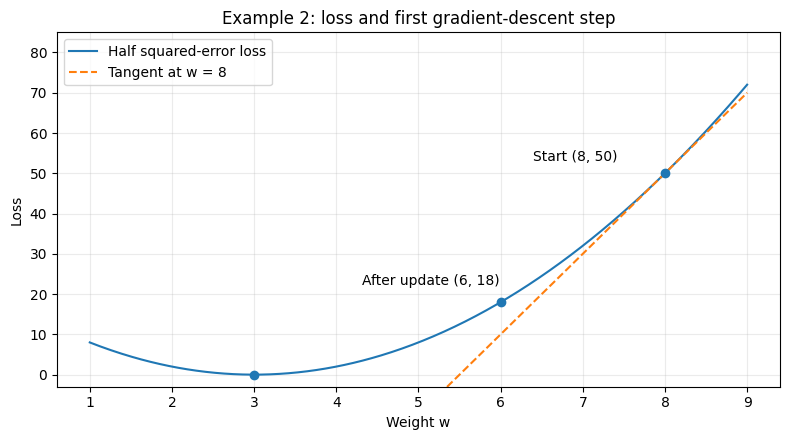

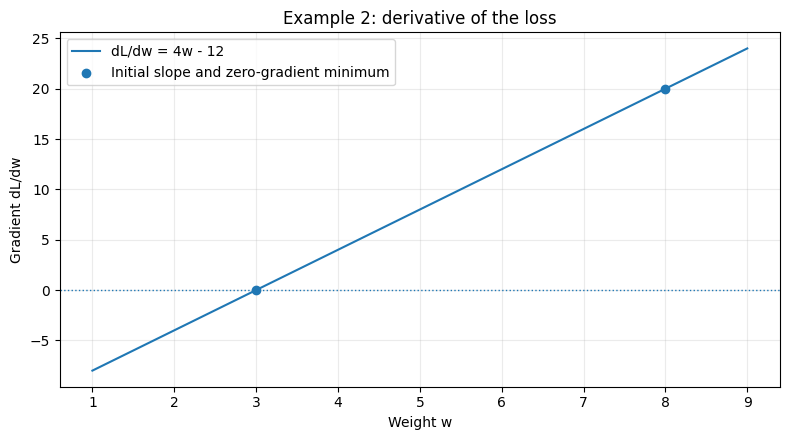

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

w = np.linspace(1.0, 9.0, 500)
loss = 0.5*(2*w - 6)**2
gradient = 2*(2*w - 6)

initial_w = 8.0
initial_loss = 0.5*(2*initial_w - 6)**2
initial_gradient = 2*(2*initial_w - 6)
new_w = initial_w - 0.1*initial_gradient
new_loss = 0.5*(2*new_w - 6)**2

tangent = initial_loss + initial_gradient*(w - initial_w)

# Plot A: loss curve, tangent at w=8, and first update.
plt.figure(figsize=(8, 4.5))
plt.plot(w, loss, label="Half squared-error loss")
plt.plot(w, tangent, "--", label="Tangent at w = 8")
plt.scatter([initial_w, new_w, 3], [initial_loss, new_loss, 0], zorder=3)
plt.annotate("Start (8, 50)", (initial_w, initial_loss), xytext=(-95, 9), textcoords="offset points")
plt.annotate("After update (6, 18)", (new_w, new_loss), xytext=(-100, 12), textcoords="offset points")
plt.xlabel("Weight w")
plt.ylabel("Loss")
plt.title("Example 2: loss and first gradient-descent step")
plt.ylim(-3, 85)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Plot B: gradient value at every weight.
plt.figure(figsize=(8, 4.5))
plt.plot(w, gradient, label="dL/dw = 4w - 12")
plt.axhline(0, linestyle=":", linewidth=1)
plt.scatter([initial_w, 3], [initial_gradient, 0], zorder=3,
            label="Initial slope and zero-gradient minimum")
plt.xlabel("Weight w")
plt.ylabel("Gradient dL/dw")
plt.title("Example 2: derivative of the loss")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

**Part B: Partial derivatives: two independent variables**

**4. What changes when a function has two variables?**

A function of two variables, such as $f(w_1,w_2)$, can change when either weight changes. A single slope is no longer enough to describe both directions.

A **partial derivative** answers a controlled question: *what happens when one weight changes slightly and the other stays fixed?*

- $\frac{\partial f}{\partial w_1}$ changes $w_1$ while holding $w_2$ fixed.
- $\frac{\partial f}{\partial w_2}$ changes $w_2$ while holding $w_1$ fixed.

The symbol $\partial$ indicates a partial derivative. **It does not mean that a partial differential equation is being solved.**


When the two partial derivatives are known, they can be collected into the gradient:

$$
\nabla f=\left(\frac{\partial f}{\partial w_1},\frac{\partial f}{\partial w_2}\right)
$$

The gradient is a pair of numbers at a chosen point. With the usual Euclidean notion of distance, it points in the direction of steepest **local increase**; its negative points toward steepest **local decrease**. An appropriate step size is still needed for the loss to decrease.


**5. Partial derivatives, Example 1: Two independent squared terms**

### 5.1 Start with the function

$$
f(w_1,w_2)=w_1^2+2w_2^2
$$

The function has two inputs, $w_1$ and $w_2$. Its graph is a bowl-like **surface** rather than a flat curve. Each location $(w_1,w_2)$ has a function value (a height).

Use the point $w_1=1$, $w_2=2$:

$$
f(1,2)=1^2+2(2^2)=\boxed{9}
$$

### 5.2 Differentiate with respect to the first variable

To calculate the partial derivative with respect to $w_1$, **treat $w_2$ as a constant**.

- The derivative of $w_1^2$ is $2w_1$.
- The derivative of $2w_2^2$ is zero because $w_2$ does not change in this calculation.

Therefore:

$$
\frac{\partial f}{\partial w_1}=2w_1
$$

At $(1,2)$:

$$
\frac{\partial f}{\partial w_1}(1,2)=2(1)=\boxed{2}
$$

With $w_2=2$ held fixed, the one-variable **slice** is $f(w_1,2)=w_1^2+8$. Its slope at $w_1=1$ is $2$.

### 5.3 Differentiate with respect to the second variable

To calculate the partial derivative with respect to $w_2$, **treat $w_1$ as a constant**.

- The derivative of $w_1^2$ is zero.
- The derivative of $2w_2^2$ is $4w_2$.

Therefore:

$$
\frac{\partial f}{\partial w_2}=4w_2
$$

At $(1,2)$:

$$
\frac{\partial f}{\partial w_2}(1,2)=4(2)=\boxed{8}
$$

With $w_1=1$ fixed, the one-variable slice is $f(1,w_2)=1+2w_2^2$. Its slope at $w_2=2$ is $8$.

### 5.4 Combine both partial derivatives

$$
\nabla f(w_1,w_2)=(2w_1,4w_2)
$$

$$
\nabla f(1,2)=\boxed{(2,8)}
$$

This means that the function is locally more sensitive to a small change in $w_2$ than to an equally small change in $w_1$ at this particular point.

For example, one gradient-descent step with $\eta=0.1$ gives:

$$
(w_1,w_2)_{\mathrm{new}}=(1,2)-0.1(2,8)=(0.8,1.2)
$$

The function falls from $9$ to $f(0.8,1.2)=0.8^2+2(1.2)^2=\boxed{3.52}$. The two derivatives were calculated at the same original point before updating either variable.

### 5.5 Calculate both partial derivatives in Python


Expected gradient: **(2, 8)**. Updated point: **(0.8, 1.2)**. Updated function value: **3.52**.


In [ ]:
import sympy as sp

w1, w2 = sp.symbols("w1 w2")
f = w1**2 + 2*w2**2

# Differentiate with respect to one variable at a time.
df_dw1 = sp.diff(f, w1)
df_dw2 = sp.diff(f, w2)

point = {w1: 1, w2: 2}
print("Function:", f)
print("df/dw1:", df_dw1)
print("df/dw2:", df_dw2)
print("f(1,2):", f.subs(point))
print("Gradient at (1,2):", (df_dw1.subs(point), df_dw2.subs(point)))

eta = 0.1
new_w1 = 1 - eta*float(df_dw1.subs(point))
new_w2 = 2 - eta*float(df_dw2.subs(point))
print("After one update:", (new_w1, new_w2))
print("New function value:", float(f.subs({w1: new_w1, w2: new_w2})))


Function: w1**2 + 2*w2**2
df/dw1: 2*w1
df/dw2: 4*w2
f(1,2): 9
Gradient at (1,2): (2, 8)
After one update: (0.8, 1.2)
New function value: 3.52



### 5.6 Visualize the function and both partial derivatives

A function of two variables can be drawn as a 3D surface. Its partial derivatives are also functions of two variables, so each derivative can be visualized as a separate surface. The marker indicates the example point.



The **function surface** has a minimum at $(0,0)$. The derivative with respect to $w_1$ changes only with $w_1$, and the derivative with respect to $w_2$ changes only with $w_2$.



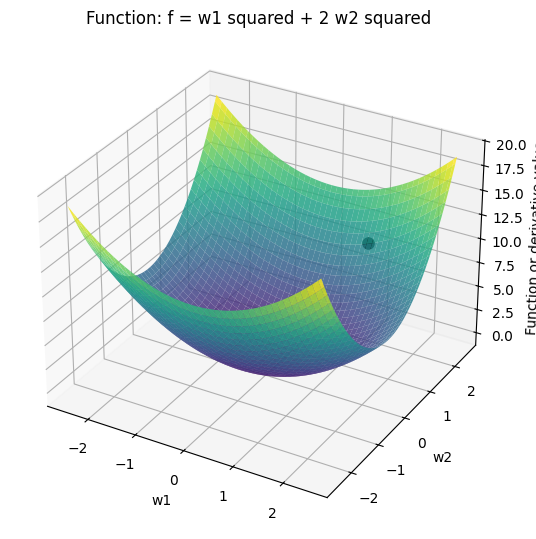

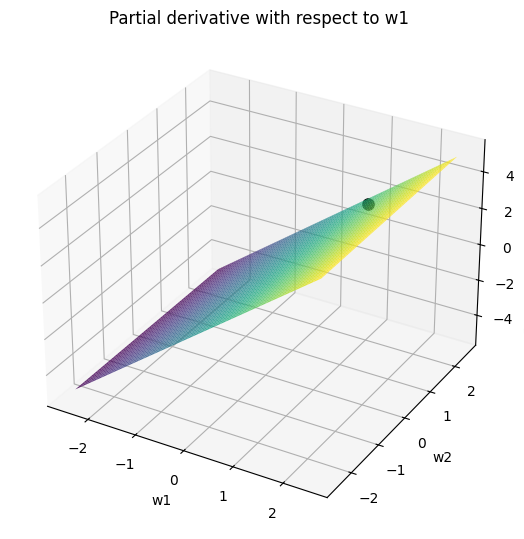

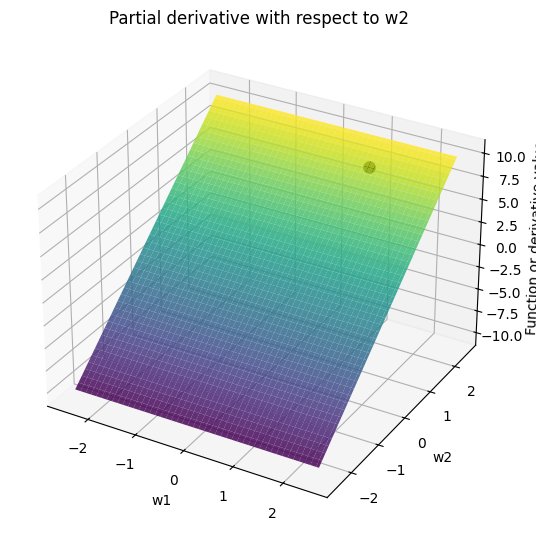

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

axis = np.linspace(-2.5, 2.5, 90)
W1, W2 = np.meshgrid(axis, axis)

F = W1**2 + 2*W2**2
D1 = 2*W1
D2 = 4*W2

# Each figure is a separate 3D surface.
for title, Z, point_z in [
    ("Function: f = w1 squared + 2 w2 squared", F, 9),
    ("Partial derivative with respect to w1", D1, 2),
    ("Partial derivative with respect to w2", D2, 8),
]:
    fig = plt.figure(figsize=(8, 5.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(W1, W2, Z, alpha=0.83, cmap="viridis")
    ax.scatter([1], [2], [point_z], s=65, color="black")
    ax.set_xlabel("w1")
    ax.set_ylabel("w2")
    ax.set_zlabel("Function or derivative value")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


### 5.7 Visualize what “holding the other variable fixed” means

Each slice is now an ordinary one-variable curve, because the other variable is fixed. The tangent slope of the first slice is $2$; the tangent slope of the second slice is $8$.



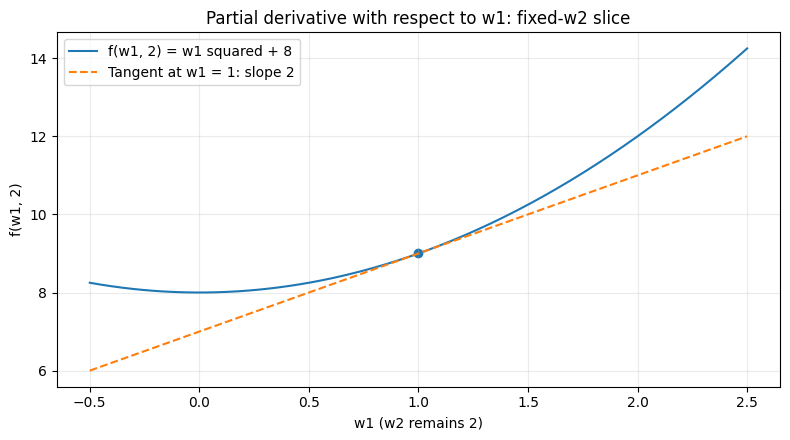

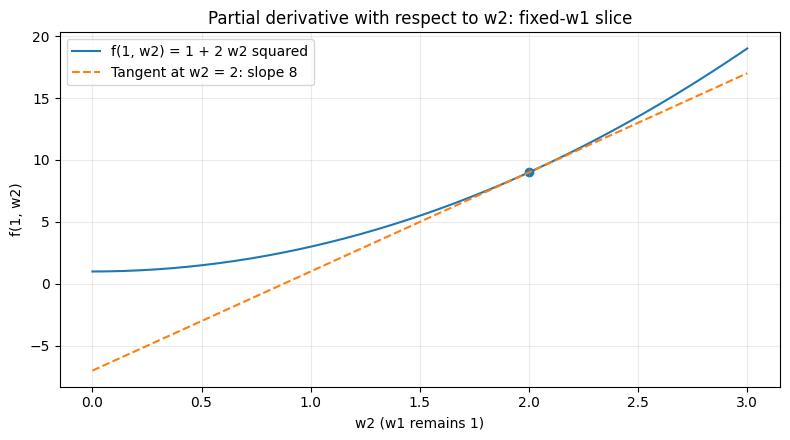

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Slice A: hold w2 = 2 fixed and change w1.
w1 = np.linspace(-0.5, 2.5, 250)
first_slice = w1**2 + 8
first_tangent = 9 + 2*(w1 - 1)

plt.figure(figsize=(8, 4.5))
plt.plot(w1, first_slice, label="f(w1, 2) = w1 squared + 8")
plt.plot(w1, first_tangent, "--", label="Tangent at w1 = 1: slope 2")
plt.scatter([1], [9])
plt.xlabel("w1 (w2 remains 2)")
plt.ylabel("f(w1, 2)")
plt.title("Partial derivative with respect to w1: fixed-w2 slice")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Slice B: hold w1 = 1 fixed and change w2.
w2 = np.linspace(0.0, 3.0, 250)
second_slice = 1 + 2*w2**2
second_tangent = 9 + 8*(w2 - 2)

plt.figure(figsize=(8, 4.5))
plt.plot(w2, second_slice, label="f(1, w2) = 1 + 2 w2 squared")
plt.plot(w2, second_tangent, "--", label="Tangent at w2 = 2: slope 8")
plt.scatter([2], [9])
plt.xlabel("w2 (w1 remains 1)")
plt.ylabel("f(1, w2)")
plt.title("Partial derivative with respect to w2: fixed-w1 slice")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

**6. Partial derivatives, Example 2: Two weights in a regression loss**

**6.1 Define the model**

A linear neuron has two fixed inputs, $x_1=2$ and $x_2=1$, and one target, $y=6$. The weights $w_1$ and $w_2$ are trainable. There is no bias.

At the initial weights (w1,w2) = (3,1)

**1. The model:** y(p) = w1x1 + w2x2 = 2w1 + w2 = 7

**2. The prediction error:** e = y(p) - y = 2w1 +w2 -6

**3. the half square error: loss** L = 0.5.(2w1 +w2 -6)** = 0.5





**6.2 Differentiate with respect to the first weight**

The loss is a chain of operations: weights determine the prediction, the prediction determines the error, and the error determines the loss.

- Loss with respect to error: $\partial L/\partial e=e$.
- Error with respect to prediction: $\partial e/\partial\hat y=1$.
- Prediction with respect to $w_1$: $\partial\hat y/\partial w_1=x_1=2$, holding $w_2$ fixed.

Multiply the three factors using the chain rule:

$$
\frac{\partial L}{\partial w_1}
=\frac{\partial L}{\partial e}
\frac{\partial e}{\partial\hat y}
\frac{\partial\hat y}{\partial w_1}
=e(1)x_1
$$

For this model:

$$
\frac{\partial L}{\partial w_1}=2(2w_1+w_2-6)
$$

At $(3,1)$:

$$
\frac{\partial L}{\partial w_1}(3,1)=(1)(2)=\boxed{2}
$$






### 6.3 Differentiate with respect to the second weight

The first two chain-rule factors do not change. Only the effect of the weight on the prediction changes:

$$
\frac{\partial\hat y}{\partial w_2}=x_2=1
$$

Therefore:

$$
\frac{\partial L}{\partial w_2}=2w_1+w_2-6
$$

At $(3,1)$:

$$
\frac{\partial L}{\partial w_2}(3,1)=(1)(1)=\boxed{1}
$$



### 6.4 Combine the derivatives and update both weights

$$
\nabla L(w_1,w_2)=\left(2(2w_1+w_2-6),\ 2w_1+w_2-6\right)
$$

At $(3,1)$:

$$
\nabla L(3,1)=\boxed{(2,1)}
$$

Backpropagation computes this gradient. Gradient descent uses it to adjust **both weights from the same original point**. For learning rate $\eta=0.1$:

$$
w_{1,\mathrm{new}}=3-0.1(2)=\boxed{2.8}
$$

$$
w_{2,\mathrm{new}}=1-0.1(1)=\boxed{0.9}
$$

The updated prediction and loss are:

$$
\hat y_{\mathrm{new}}=(2.8)(2)+(0.9)(1)=6.5
$$

$$
L_{\mathrm{new}}=\frac12(6.5-6)^2=\boxed{0.125}
$$

The loss decreases from **0.5** to **0.125**. The mathematical operation is the same chain rule used in the one-weight example; only the number of independently adjustable parameters has changed.

**6.5 Calculate both partial derivatives in Python**

In [ ]:
import sympy as sp

w1, w2 = sp.symbols("w1 w2")
x1, x2, y = 2, 1, 6

prediction = w1*x1 + w2*x2
loss = sp.Rational(1, 2)*(prediction - y)**2

dloss_dw1 = sp.diff(loss, w1)
dloss_dw2 = sp.diff(loss, w2)
point = {w1: 3, w2: 1}

print("Loss:", loss)
print("Partial w1:", sp.expand(dloss_dw1))
print("Partial w2:", sp.expand(dloss_dw2))
print("Initial loss:", loss.subs(point))
print("Initial gradient:", (dloss_dw1.subs(point), dloss_dw2.subs(point)))

eta = 0.1
new_w1 = 3 - eta*float(dloss_dw1.subs(point))
new_w2 = 1 - eta*float(dloss_dw2.subs(point))
print("New weights:", (new_w1, new_w2))
print("New loss:", float(loss.subs({w1: new_w1, w2: new_w2})))

Loss: (2*w1 + w2 - 6)**2/2
Partial w1: 4*w1 + 2*w2 - 12
Partial w2: 2*w1 + w2 - 6
Initial loss: 1/2
Initial gradient: (2, 1)
New weights: (2.8, 0.9)
New loss: 0.12499999999999983


**6.6 Visualize the loss and the two partial derivatives**

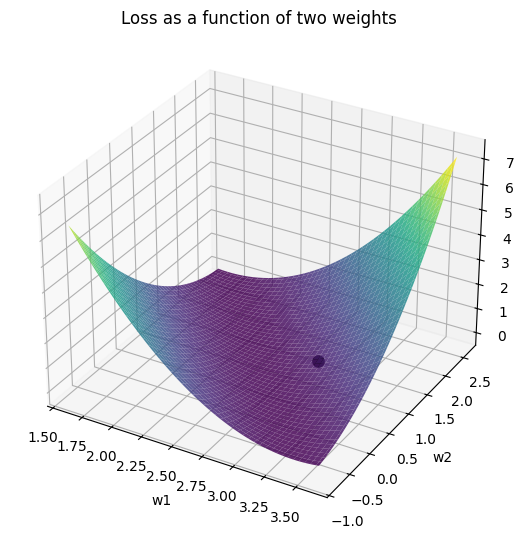

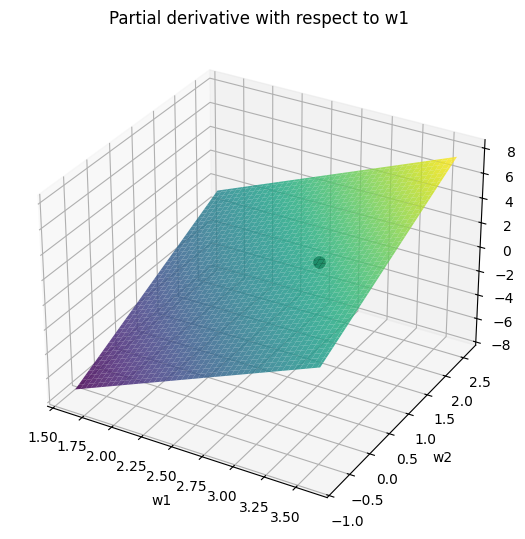

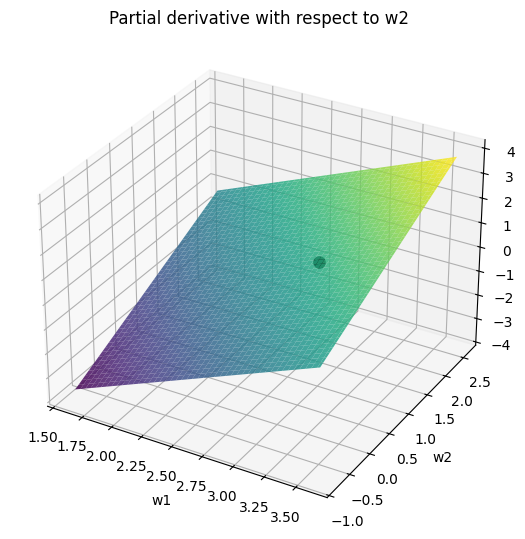

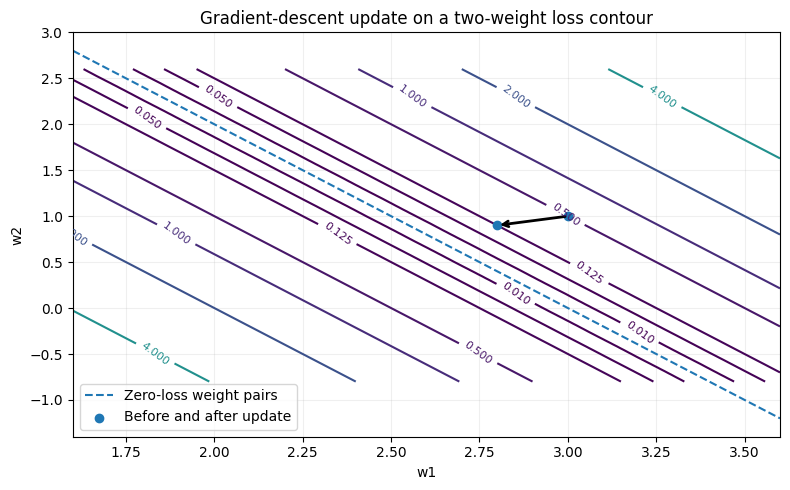

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

w1_axis = np.linspace(1.6, 3.6, 90)
w2_axis = np.linspace(-0.8, 2.6, 90)
W1, W2 = np.meshgrid(w1_axis, w2_axis)

error = 2*W1 + W2 - 6
loss = 0.5*error**2
dL_dw1 = 2*error
dL_dw2 = error

# Three separate 3D surfaces: loss, partial w1, and partial w2.
for title, Z, marked_z in [
    ("Loss as a function of two weights", loss, 0.5),
    ("Partial derivative with respect to w1", dL_dw1, 2.0),
    ("Partial derivative with respect to w2", dL_dw2, 1.0),
]:
    fig = plt.figure(figsize=(8, 5.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(W1, W2, Z, alpha=0.83, cmap="viridis")
    ax.scatter([3], [1], [marked_z], s=65, color="black")
    ax.set_xlabel("w1")
    ax.set_ylabel("w2")
    ax.set_zlabel("Loss or derivative")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

# Contour view: same loss, viewed from above.
plt.figure(figsize=(8, 5))
levels = [0.01, 0.05, 0.125, 0.5, 1, 2, 4, 8]
contours = plt.contour(W1, W2, loss, levels=levels)
plt.clabel(contours, inline=True, fontsize=8)
plt.plot(w1_axis, 6 - 2*w1_axis, "--", label="Zero-loss weight pairs")
plt.scatter([3, 2.8], [1, 0.9], label="Before and after update", zorder=3)
plt.annotate("", xy=(2.8, 0.9), xytext=(3, 1),
             arrowprops={"arrowstyle": "->", "lw": 2})
plt.xlabel("w1")
plt.ylabel("w2")
plt.title("Gradient-descent update on a two-weight loss contour")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

**6.7 Visualize fixed-variable slices**

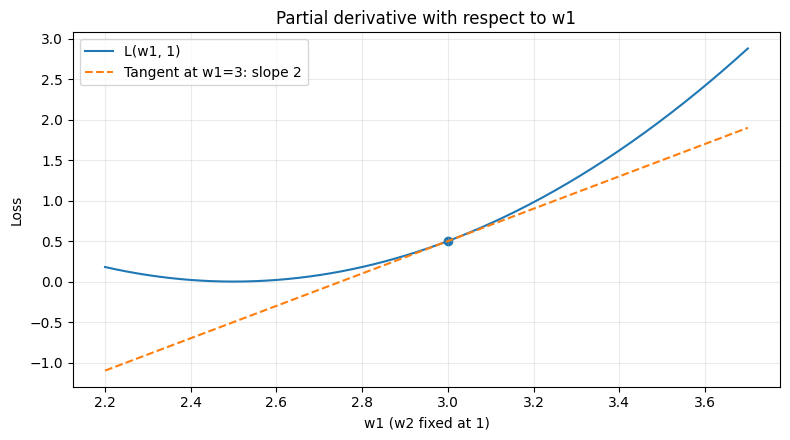

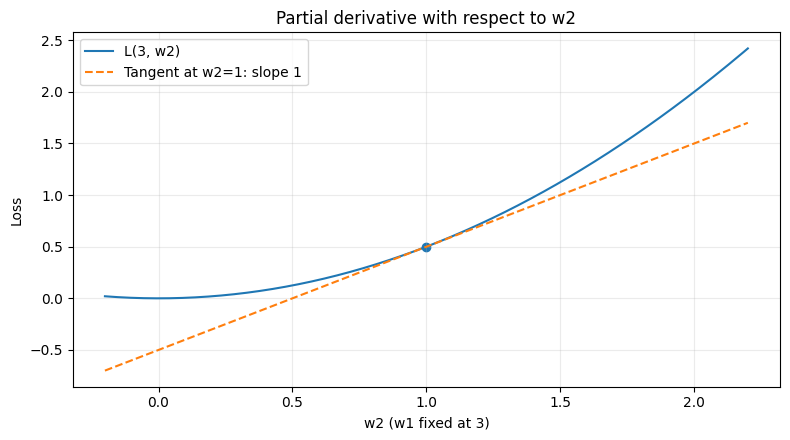

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Slice A: hold w2 = 1 fixed.
w1 = np.linspace(2.2, 3.7, 300)
loss_slice_w1 = 0.5*(2*w1 + 1 - 6)**2
tangent_w1 = 0.5 + 2*(w1 - 3)

plt.figure(figsize=(8, 4.5))
plt.plot(w1, loss_slice_w1, label="L(w1, 1)")
plt.plot(w1, tangent_w1, "--", label="Tangent at w1=3: slope 2")
plt.scatter([3], [0.5])
plt.xlabel("w1 (w2 fixed at 1)")
plt.ylabel("Loss")
plt.title("Partial derivative with respect to w1")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Slice B: hold w1 = 3 fixed.
w2 = np.linspace(-0.2, 2.2, 300)
loss_slice_w2 = 0.5*(2*3 + w2 - 6)**2
tangent_w2 = 0.5 + 1*(w2 - 1)

plt.figure(figsize=(8, 4.5))
plt.plot(w2, loss_slice_w2, label="L(3, w2)")
plt.plot(w2, tangent_w2, "--", label="Tangent at w2=1: slope 1")
plt.scatter([1], [0.5])
plt.xlabel("w2 (w1 fixed at 3)")
plt.ylabel("Loss")
plt.title("Partial derivative with respect to w2")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

**7. Comparing the four examples**

| Example | Function | Derivative(s) | Point | Derivative value(s) |
|---|---|---|---|---|
| Ordinary 1 | $f(w)=w^2$ | $f'(w)=2w$ | $w=2$ | $4$ |
| Ordinary 2 | $L(w)=\frac12(2w-6)^2$ | $L'(w)=4w-12$ | $w=8$ | $20$ |
| Partial 1 | $f(w_1,w_2)=w_1^2+2w_2^2$ | $\frac{\partial f}{\partial w_1}=2w_1$; $\frac{\partial f}{\partial w_2}=4w_2$ | $(1,2)$ | $(2,8)$ |
| Partial 2 | $L(w_1,w_2)=\frac12(2w_1+w_2-6)^2$ | $\frac{\partial L}{\partial w_1}=2(2w_1+w_2-6)$; $\frac{\partial L}{\partial w_2}=2w_1+w_2-6$ | $(3,1)$ | $(2,1)$ |